# Assignment 4

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

In [2]:
def freq_to_spatial(img):
    return np.fft.ifft2(np.fft.ifftshift(img)).real

def plot_histogram(img, name):
    for i, col in enumerate(['r', 'g', 'b']):
        hist = cv2.calcHist([img], [i], None, [256], [0, 256])
        plt.plot(hist, color=col)
        plt.title(f'{name}')
        plt.xlim([0, 256])

## Question 1

In this problem, you will use your image processing knowledge to repair a corrupted image.  
Remove the lines and artifacts from the corrupted *“fruits.png”* image.

<img src="./imgs/fruits.png" width="200" height="200"/>

(-0.5, 510.5, 509.5, -0.5)

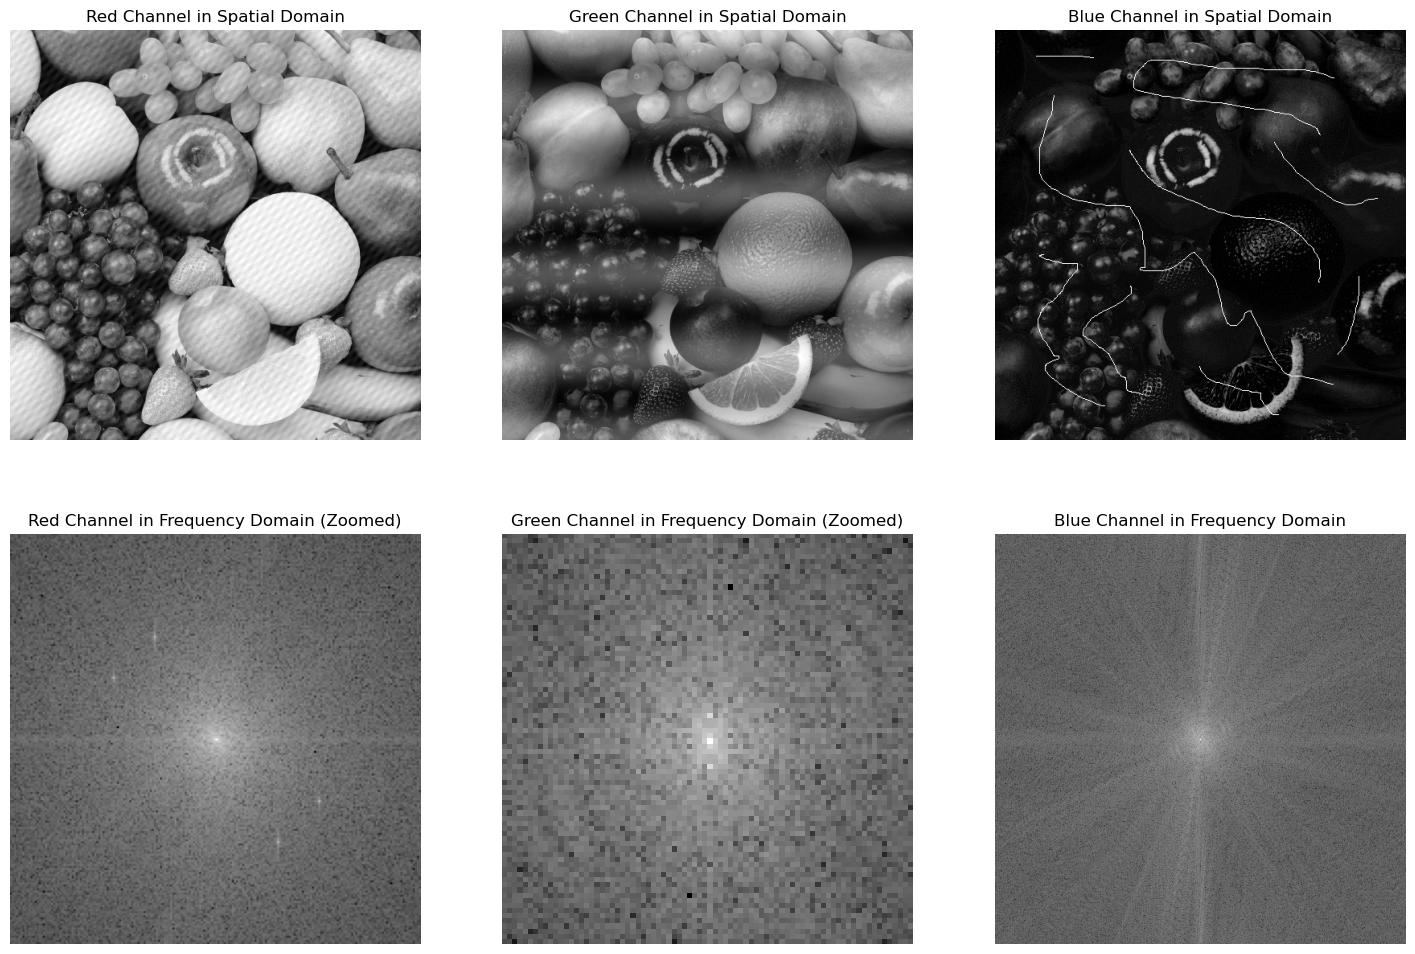

In [3]:
# Reading the corrupted image, separating its RGB channels, and analyzing their frequency spectra.

ex1_image = cv2.imread('./imgs/fruits.png')
ex1_image = cv2.cvtColor(ex1_image, cv2.COLOR_BGR2RGB)
ex1_orig = ex1_image.copy()

ex1_r = ex1_image[:,:,0]
ex1_g = ex1_image[:,:,1]
ex1_b = ex1_image[:,:,2]

ex1_r_copy = ex1_r.copy()
ex1_g_copy = ex1_g.copy()
ex1_b_copy = ex1_b.copy()

ex1_r_fft = np.fft.fft2(ex1_r)
ex1_r_shift = np.fft.fftshift(ex1_r_fft)

ex1_g_fft = np.fft.fft2(ex1_g)
ex1_g_shift = np.fft.fftshift(ex1_g_fft)

ex1_b_fft = np.fft.fft2(ex1_b)
ex1_b_shift = np.fft.fftshift(ex1_b_fft)

plt.figure(figsize=(18,12))

plt.subplot(2,3,1)
plt.title('Red Channel in Spatial Domain')
plt.imshow(ex1_r, cmap='gray')
plt.axis('off')

plt.subplot(2,3,4)
plt.title('Red Channel in Frequency Domain (Zoomed)')
plt.imshow(np.log1p(np.abs(ex1_r_shift))[155:355,155:355], cmap='gray')
plt.axis('off')

plt.subplot(2,3,2)
plt.title('Green Channel in Spatial Domain')
plt.imshow(ex1_g, cmap='gray')
plt.axis('off')

plt.subplot(2,3,5)
plt.title('Green Channel in Frequency Domain (Zoomed)')
plt.imshow(np.log1p(np.abs(ex1_g_shift))[215:295,215:295], cmap='gray')
plt.axis('off')

plt.subplot(2,3,3)
plt.title('Blue Channel in Spatial Domain')
plt.imshow(ex1_b, cmap='gray')
plt.axis('off')

plt.subplot(2,3,6)
plt.title('Blue Channel in Frequency Domain')
plt.imshow(np.log1p(np.abs(ex1_b_shift)), cmap='gray')
plt.axis('off')

#plt.savefig('figs/q1.jpg', format='jpg', bbox_inches="tight", pad_inches=0)

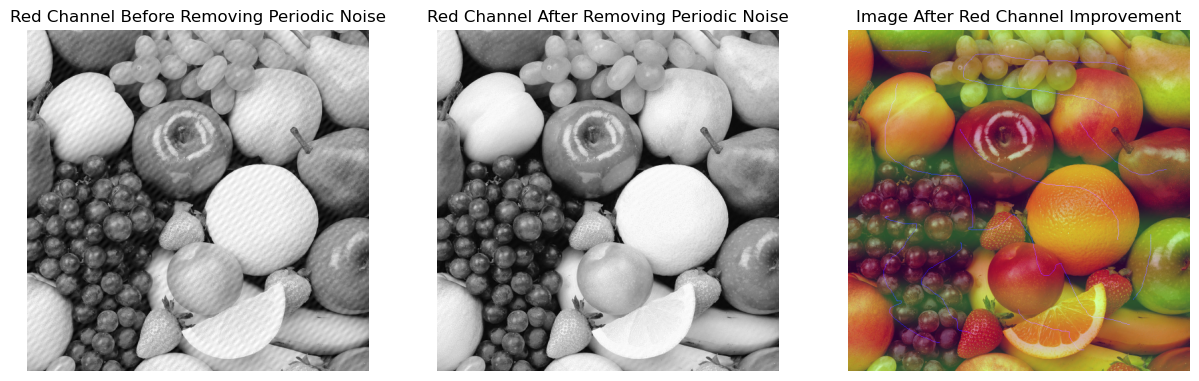

In [4]:
# Removing periodic noise from the red channel using frequency-domain filtering.

ex1_r_shift[203:208,224:227] = 0
ex1_r_shift[223:228,204:207] = 0
ex1_r_shift[283:288,304:307] = 0
ex1_r_shift[303:308,284:287] = 0

ex1_r = freq_to_spatial(ex1_r_shift)
ex1_image[:,:,0] = ex1_r

plt.figure(figsize=(15,15))

plt.subplot(1,3,1)
plt.title('Red Channel Before Removing Periodic Noise')
plt.imshow(ex1_r_copy, cmap='gray')
plt.axis('off')

plt.subplot(1,3,2)
plt.title('Red Channel After Removing Periodic Noise')
plt.imshow(ex1_r, cmap='gray')
plt.axis('off')

plt.subplot(1,3,3)
plt.title('Image After Red Channel Improvement')
plt.imshow(ex1_image)
plt.axis('off');

#plt.savefig('figs/q1-1.jpg', format='jpg', bbox_inches="tight", pad_inches=0)

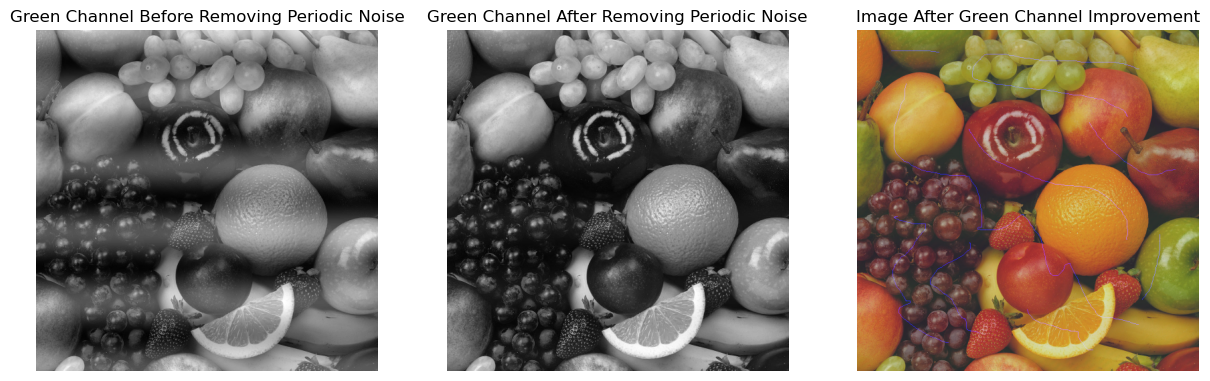

In [5]:
# Removing periodic noise from the green channel using frequency-domain filtering.

ex1_g_shift[250, 255] = 0
ex1_g_shift[260, 255] = 0

ex1_g = freq_to_spatial(ex1_g_shift)
ex1_image[:,:,1] = ex1_g

plt.figure(figsize=(15,15))

plt.subplot(1,3,1)
plt.title('Green Channel Before Removing Periodic Noise')
plt.imshow(ex1_g_copy, cmap='gray')
plt.axis('off')

plt.subplot(1,3,2)
plt.title('Green Channel After Removing Periodic Noise')
plt.imshow(ex1_g, cmap='gray')
plt.axis('off')

plt.subplot(1,3,3)
plt.title('Image After Green Channel Improvement')
plt.imshow(ex1_image)
plt.axis('off');

#plt.savefig('figs/q1-2.jpg', format='jpg', bbox_inches="tight", pad_inches=0)

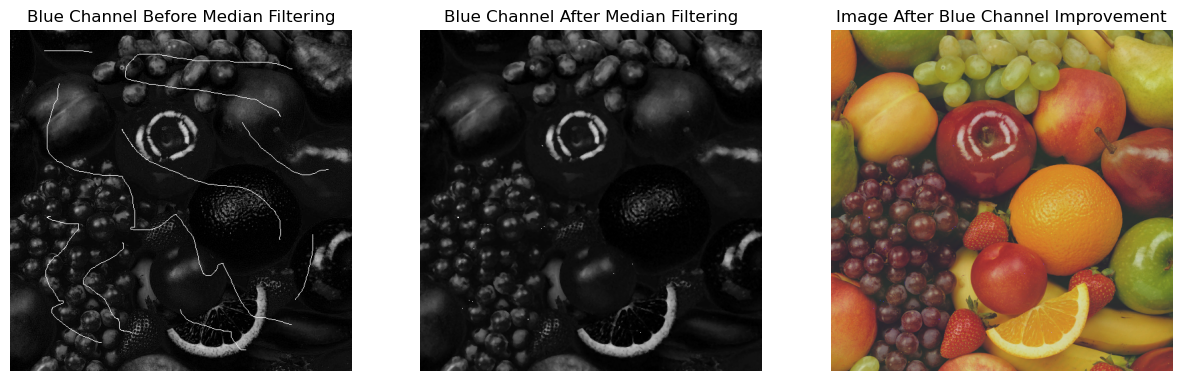

In [6]:
# Removing noise from the blue channel using median filtering.

ex1_b_new = cv2.medianBlur(ex1_b, 3)
ex1_image[:,:,2] = ex1_b_new

plt.figure(figsize=(15,15))

plt.subplot(1,3,1)
plt.title('Blue Channel Before Median Filtering')
plt.imshow(ex1_b_copy, cmap='gray')
plt.axis('off')

plt.subplot(1,3,2)
plt.title('Blue Channel After Median Filtering')
plt.imshow(ex1_b_new, cmap='gray')
plt.axis('off')

plt.subplot(1,3,3)
plt.title('Image After Blue Channel Improvement')
plt.imshow(ex1_image)
plt.axis('off');

#plt.savefig('figs/q1-3.jpg', format='jpg', bbox_inches="tight", pad_inches=0)

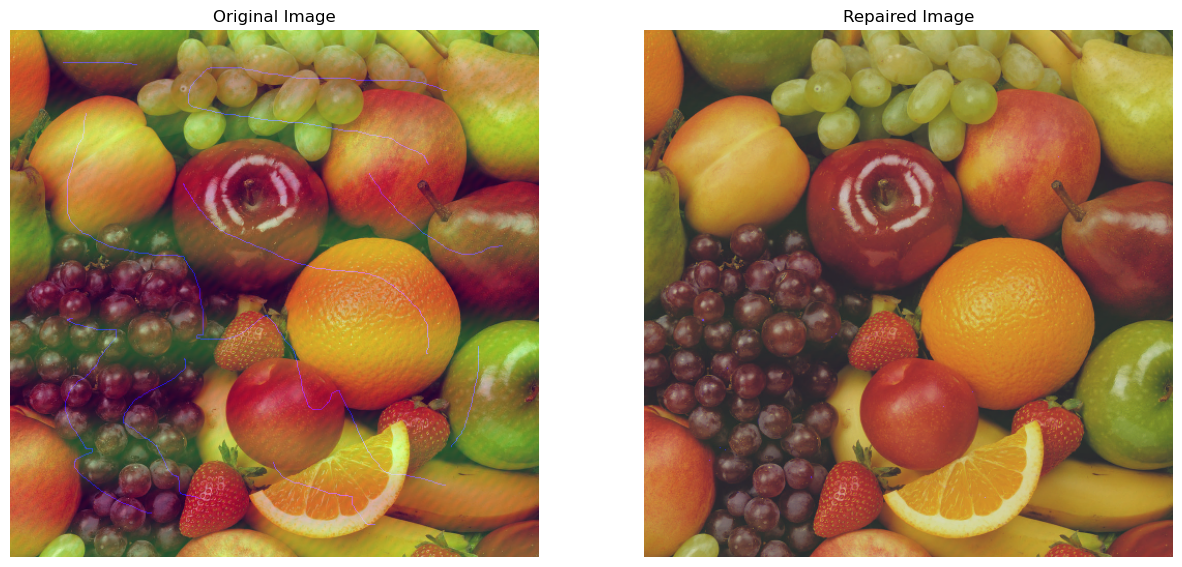

In [7]:
# Comparing the original image with the fully repaired image.

plt.figure(figsize=(15,15))

plt.subplot(1,2,1)
plt.title('Original Image')
plt.imshow(ex1_orig)
plt.axis('off')

plt.subplot(1,2,2)
plt.title('Repaired Image')
plt.imshow(ex1_image)
plt.axis('off');

#plt.savefig('figs/q1-4.jpg', format='jpg', bbox_inches="tight", pad_inches=0)

## Question 2

Apply histogram equalization to tune the low-exposure image *“badexposure.jpg”*.  
Show the histograms before and after applying the histogram equalization algorithm.

<img src="./imgs/badexposure.jpg" width="200" height="200"/>

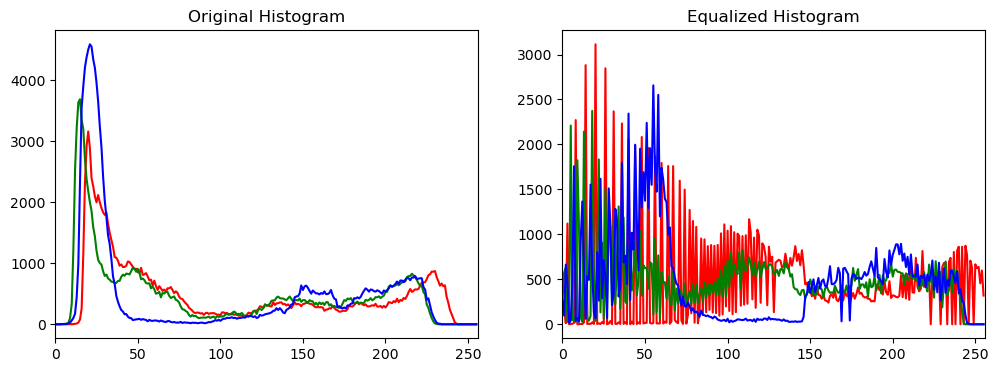

In [8]:
# Applying histogram equalization to the Value channel and comparing the original and equalized histograms.
ex2_image = cv2.imread('./imgs/badexposure.jpg')
ex2_image = cv2.cvtColor(ex2_image, cv2.COLOR_BGR2RGB)

ex2_hsv = cv2.cvtColor(ex2_image, cv2.COLOR_RGB2HSV)
ex2_hsv[:, :, 2] = cv2.equalizeHist(ex2_hsv[:, :, 2])  
ex2_equalized = cv2.cvtColor(ex2_hsv, cv2.COLOR_HSV2RGB)  
        
plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plot_histogram(ex2_image, 'Original Histogram')

plt.subplot(1,2,2)
plot_histogram(ex2_equalized, 'Equalized Histogram')
#plt.savefig('./results/q2-1.jpg', format='jpg', bbox_inches="tight", pad_inches=0)

(-0.5, 431.5, 287.5, -0.5)

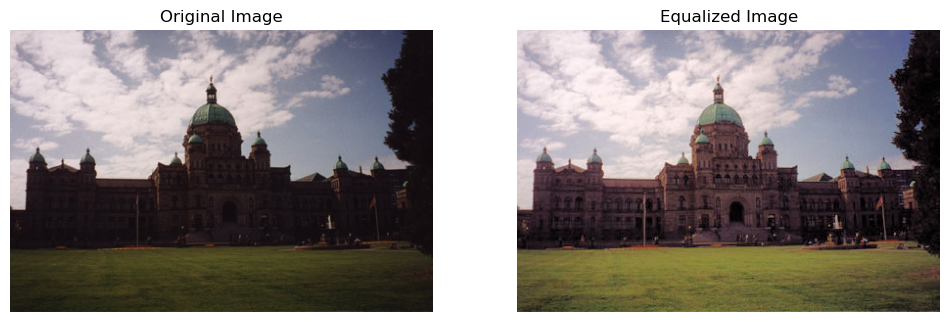

In [9]:
plt.figure(figsize=(12,6))

plt.subplot(1,2,1)
plt.title('Original Image')
plt.imshow(ex2_image)
plt.axis('off')

plt.subplot(1,2,2)
plt.title('Equalized Image')
plt.imshow(ex2_equalized)
plt.axis('off')
#plt.savefig('./results/q2-2.jpg', format='jpg', bbox_inches="tight", pad_inches=0)

## Question 3

**A)** Remove the noise from the image *“splash.png*.    
**B)** Separate the two types of blobs in the *“blobs.png”*.


<div style="display: flex;">
    <img src="./imgs/splash.png" alt="Image 1" width="200" height="200"/>
    <img src="./imgs/blobs.png" alt="Image 2" width="200" height="200"/>
</div>


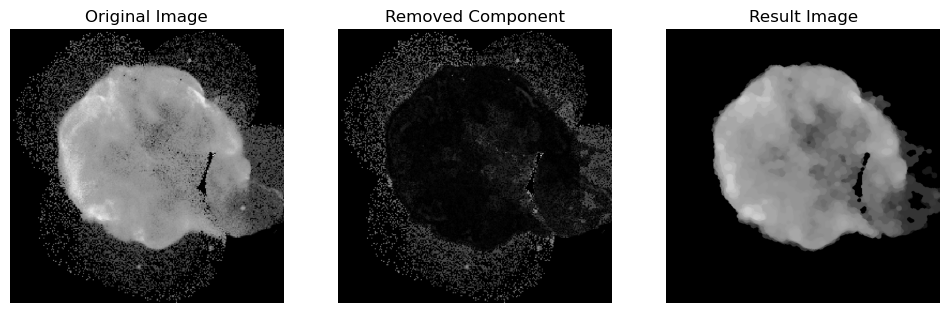

In [10]:
# Answer for A : Removing noise using morphological opening and closing operations.
ex3_a = cv2.imread('./imgs/splash.png')

radius = 5
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2*radius+1, 2*radius+1), (radius, radius))
opened = cv2.morphologyEx(ex3_a, cv2.MORPH_OPEN, kernel)

radius = 3
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2*radius+1, 2*radius+1), (radius, radius))
result = cv2.morphologyEx(opened, cv2.MORPH_CLOSE, kernel)

removed = cv2.absdiff(ex3_a, result)

plt.figure(figsize=(12,12))

plt.subplot(1,3,1)
plt.title('Original Image')
plt.axis('off')
plt.imshow(ex3_a, cmap='gray')

plt.subplot(1,3,2)
plt.title('Removed Component')
plt.axis('off')
plt.imshow(removed, cmap='gray')

plt.subplot(1,3,3)
plt.title('Result Image')
plt.axis('off')
plt.imshow(result, cmap='gray')
#plt.savefig('./results/q3a.jpg', format='jpg', bbox_inches="tight", pad_inches=0)

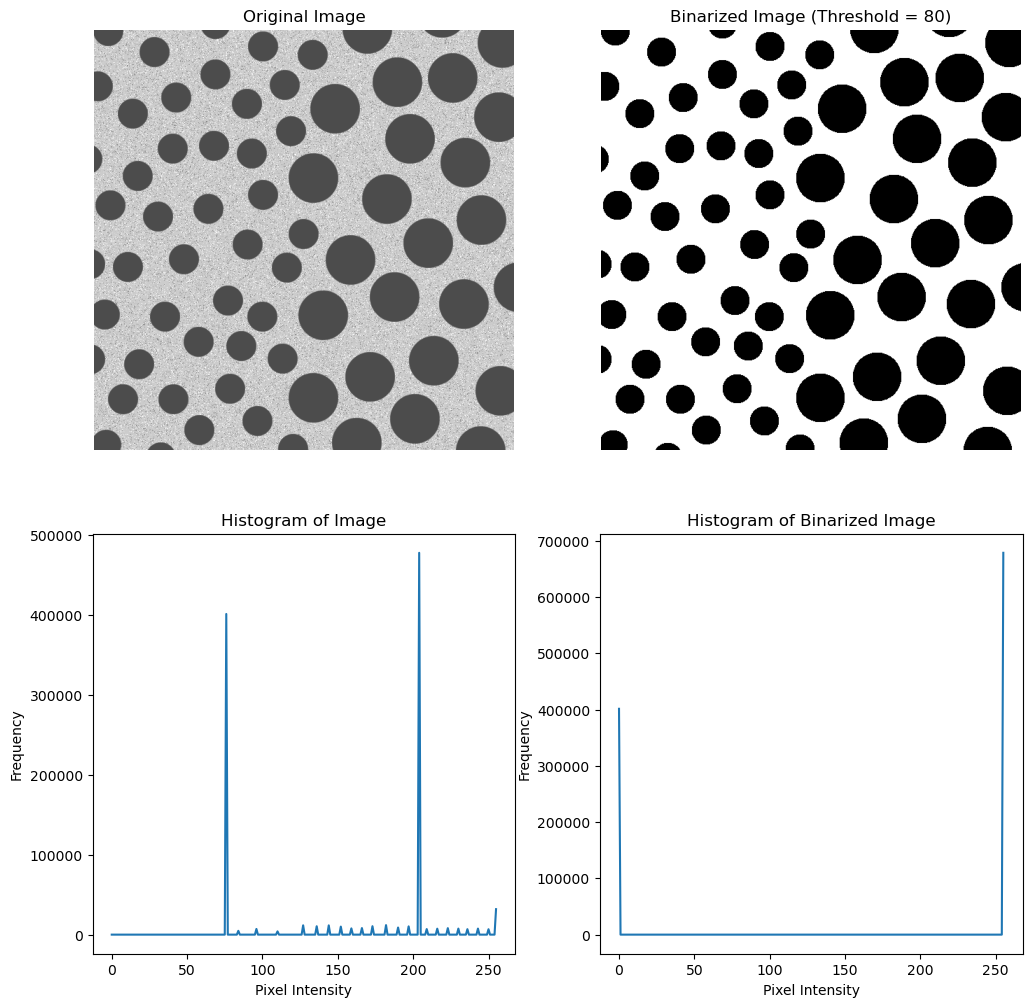

In [11]:
# Answer for B : Applying thresholding and analyzing the intensity histograms to separate the two types of blobs.
ex3_b = cv2.imread('./imgs/blobs.png')
plt.figure(figsize=(12,12))
plt.subplot(2,2,1)
plt.title('Original Image')
plt.imshow(ex3_b, cmap='gray')
plt.axis('off')

hist, bins = np.histogram(ex3_b.flatten(), bins=256, range=[0,256])
plt.subplot(2,2,3)
plt.title('Histogram of Image')
plt.xlabel('Pixel Intensity')
plt.ylabel('Frequency')
plt.plot(hist)

ex3_b[ex3_b < 80] = 0
ex3_b[ex3_b >= 80] = 255

plt.subplot(2,2,2)
plt.title('Binarized Image (Threshold = 80)')
plt.axis('off')
plt.imshow(ex3_b, cmap='gray')

hist, bins = np.histogram(ex3_b.flatten(), bins=256, range=[0,256])
plt.subplot(2,2,4)
plt.title('Histogram of Binarized Image')
plt.xlabel('Pixel Intensity')
plt.ylabel('Frequency')
plt.plot(hist)
#plt.savefig('./results/q3b1.jpg', format='jpg', bbox_inches="tight", pad_inches=0)

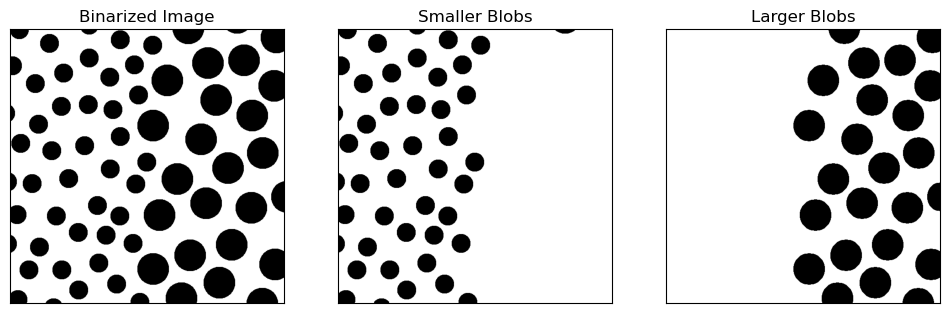

In [12]:
	# Answer for B : Separating larger and smaller blobs using morphological operations.
radius_large = 25
kernel_large = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2*radius_large+1, 2*radius_large+1), (radius_large, radius_large))
closed_large = cv2.morphologyEx(ex3_b, cv2.MORPH_CLOSE, kernel_large)

inverted = (255 - closed_large)
no_big = ex3_b + inverted

radius_small = 5
kernel_small = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2*radius_small+1, 2*radius_small+1), (radius_small, radius_small))
closed_small = cv2.morphologyEx(no_big, cv2.MORPH_CLOSE, kernel_small)

plt.figure(figsize=(12,8))

plt.subplot(1,3,1)
plt.imshow(ex3_b, cmap='gray')
plt.title('Binarized Image')
plt.xticks([]), plt.yticks([])

plt.subplot(1,3,3)
plt.imshow(closed_large, cmap='gray')
plt.title('Larger Blobs')
plt.xticks([] ), plt.yticks([])

plt.subplot(1,3,2)
plt.imshow(closed_small, cmap='gray')
plt.title('Smaller Blobs')
plt.xticks([]), plt.yticks([]);
#plt.savefig('./results/q3b2.jpg', format='jpg', bbox_inches="tight", pad_inches=0)

## Question 4

The image *“rices.png”* includes objects of rice grains of different orientations over a dark background.     
In this problem, you are asked to develop a program to:     

**A)** Detect (extract from the background) the rice grain objects (By example, using thresholding)     
**B)** Compute the number and average size of the rice grains. (Use the morphological operations to count the number of rice grains, such as Opening, Closing connected components, and …)


<img src="./imgs/rices.png" width="200" height="200"/>

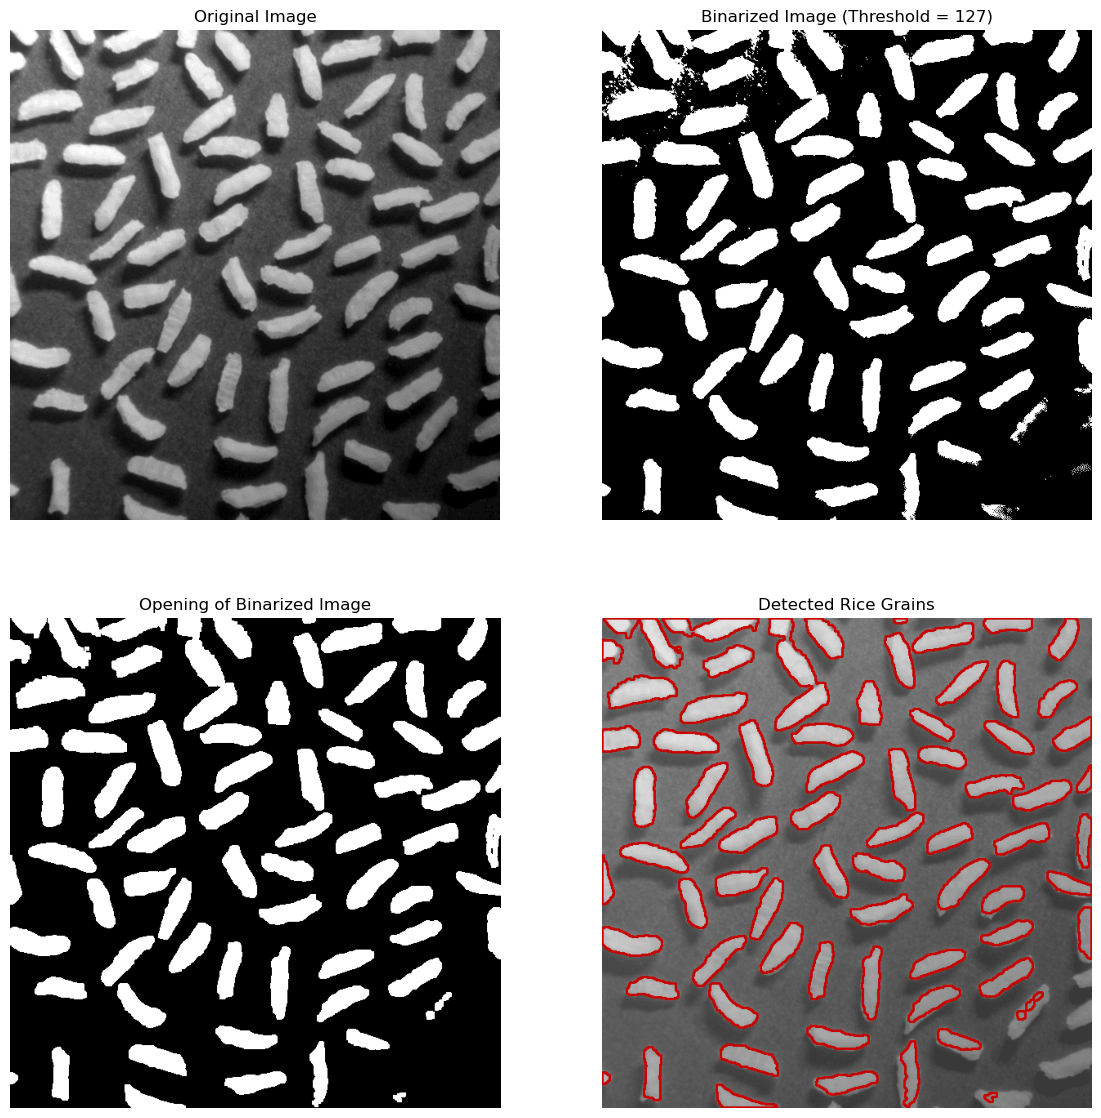

In [13]:
# Answer for A : Extracting rice grains from the background using thresholding and morphological opening.
ex4_image = cv2.imread('./imgs/rices.png', 0)
ex4_image_orig = ex4_image.copy()

ex4_image[ex4_image <= 127] = 0
ex4_image[ex4_image > 127] = 255

kernel = np.ones((5, 5),np.uint8)
opened = cv2.morphologyEx(ex4_image, cv2.MORPH_OPEN, kernel)

contours, hierarchy = cv2.findContours(opened, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
countour = cv2.cvtColor(ex4_image_orig, cv2.COLOR_GRAY2BGR)
cv2.drawContours(countour, contours, -1, (200, 0, 0), 2)

plt.figure(figsize=(14,14))

plt.subplot(2,2,1)
plt.title('Original Image')
plt.axis('off')
plt.imshow(ex4_image_orig, cmap='gray')

plt.subplot(2,2,2)
plt.title('Binarized Image (Threshold = 127)')
plt.axis('off')
plt.imshow(ex4_image, cmap='gray')

plt.subplot(2,2,3)
plt.title('Opening of Binarized Image')
plt.axis('off')
plt.imshow(opened, cmap='gray')

plt.subplot(2,2,4)
plt.title('Detected Rice Grains')
plt.axis('off')
plt.imshow(countour)
#plt.savefig('./results/q4.jpg', format='jpg', bbox_inches="tight", pad_inches=0)

In [14]:
# Answer for B : Calculating the number and average area of the detected rice grains.
avg_size = sum(cv2.contourArea(cnt) for cnt in contours) / len(contours)

print("Number of rice grains:", len(contours))
print(f"Average size of rice grains: {avg_size:.2f} pixels")

Number of rice grains: 74
Average size of rice grains: 1256.93 pixels
